# 07 · LoRA fine-tuning on COCO food scenes

**IE 7615 · From Words to Worlds**

Train a small SD 1.5 attention adapter on COCO `train2017` captions about food. Then compare the pretrained model and the adapter on a fixed set of COCO `val2017` captions. The notebook records the training process and produces a paired image comparison. Changes in the images are evidence for inspection, and any improvement is an empirical question.

In Google Colab, choose **Runtime → Change runtime type → GPU** and run sections 01–09 in order. Authorize the Drive mount. Uploading this notebook directly is sufficient. The first run downloads the checkpoint, official caption annotations, and the selected training JPEGs. The annotation archive includes both splits. There is no bulk COCO image download.

The training loop follows the [maintained Diffusers LoRA example](https://huggingface.co/docs/diffusers/training/lora), using PEFT attention adapters, frozen pretrained components, and a diffusion denoising loss. This notebook uses PyTorch autocast and GradScaler on one GPU so the accumulation and resume logic are visible.

## 01 · Set up the Colab GPU

Use the CUDA-enabled PyTorch already installed by Colab. The dependency cell keeps its version and the versions of installed TorchVision and TorchAudio, installs the Notebook 05/06 inference pins plus PEFT, and checks the imports and an FP16 CUDA operation before loading weights. If prompted to restart, restart the session and run from section 01.

In [1]:
import importlib.metadata as metadata
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path
from tempfile import TemporaryDirectory

import torch
from packaging.version import Version

if sys.version_info < (3, 11):
    raise RuntimeError("Select a Colab runtime with Python 3.11 or newer.")
if not torch.cuda.is_available() or torch.version.cuda is None:
    raise RuntimeError("Select a GPU under Runtime → Change runtime type and rerun this cell.")
if Version(torch.__version__).release < (2, 6):
    raise RuntimeError("Select a Colab GPU runtime with PyTorch 2.6 or newer.")

device = torch.device("cuda", torch.cuda.current_device())
dtype = torch.float16
try:
    probe = torch.ones((8, 8), device=device, dtype=dtype)
    if (probe @ probe)[0, 0].item() != 8.0:
        raise RuntimeError("The FP16 CUDA probe returned an unexpected result.")
    del probe
except RuntimeError as error:
    raise RuntimeError("Choose an NVIDIA GPU runtime with working FP16 support.") from error

inference_pins = {
    "diffusers": "0.42.1",
    "transformers": "5.22.1",
    "accelerate": "1.15.0",
    "safetensors": "0.8.0",
    "peft": "0.21.3",
}
runtime_packages = {
    dist.metadata["Name"].lower(): dist.version
    for dist in metadata.distributions()
    if dist.metadata["Name"]
}
torch_packages = {
    name: runtime_packages[name]
    for name in ("torch", "torchvision", "torchaudio")
    if name in runtime_packages
}
if any(runtime_packages.get(name) != version for name, version in inference_pins.items()):
    was_imported = any(
        name in sys.modules
        for name in (*inference_pins, "huggingface_hub", "tokenizers")
    )
    with TemporaryDirectory() as temp_dir:
        constraints = Path(temp_dir) / "colab-torch.txt"
        constraints.write_text(
            "".join(f"{name}=={version}\n" for name, version in torch_packages.items()),
            encoding="utf-8",
        )
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "--constraint", str(constraints)]
            + [f"{name}=={version}" for name, version in inference_pins.items()],
            check=True,
        )
    if was_imported:
        raise RuntimeError("Inference libraries were already imported. Restart the Colab session and run again.")

for name, version in {**torch_packages, **inference_pins}.items():
    if metadata.version(name) != version:
        raise RuntimeError(f"{name} version differs from the expected {version}.")

import numpy as np
from diffusers import StableDiffusionPipeline
from PIL import Image
from diffusers.utils import USE_PEFT_BACKEND
from peft import LoraConfig

if not USE_PEFT_BACKEND:
    raise RuntimeError("Diffusers could not activate its PEFT backend. Restart the runtime and rerun this cell.")
if not all(hasattr(StableDiffusionPipeline, name) for name in ("save_lora_weights", "load_lora_weights", "disable_lora", "enable_lora")):
    raise RuntimeError("The installed Diffusers pipeline is missing required LoRA APIs.")

gpu = torch.cuda.get_device_properties(device)
driver_info = None
if nvidia_smi := shutil.which("nvidia-smi"):
    driver_query = subprocess.run(
        [nvidia_smi, "--query-gpu=index,name,driver_version", "--format=csv,noheader"],
        capture_output=True,
        text=True,
        check=False,
    )
    driver_info = driver_query.stdout.strip() or None
runtime_info = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "device": str(device),
    "gpu": gpu.name,
    "compute_capability": [gpu.major, gpu.minor],
    "gpu_total_memory_bytes": gpu.total_memory,
    "nvidia_smi": driver_info,
    "torch_cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version(),
    "packages": {
        name: metadata.version(name)
        for name in (*torch_packages, *inference_pins, "huggingface-hub", "tokenizers", "numpy", "pillow", "matplotlib", "requests")
    },
}
print(json.dumps(runtime_info, indent=2))

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "device": "cuda:0",
  "gpu": "Tesla T4",
  "compute_capability": [
    7,
    5
  ],
  "gpu_total_memory_bytes": 15637086208,
  "nvidia_smi": "0, Tesla T4, 580.82.07",
  "torch_cuda": "13.0",
  "cudnn": 92800,
  "packages": {
    "torch": "2.14.1+cu130",
    "torchvision": "0.29.1+cu130",
    "torchaudio": "2.11.0+cu130",
    "diffusers": "0.42.1",
    "transformers": "5.22.1",
    "accelerate": "1.15.0",
    "safetensors": "0.8.0",
    "peft": "0.21.3",
    "huggingface-hub": "1.33.0",
    "tokenizers": "0.23.3",
    "numpy": "2.4.6",
    "pillow": "11.3.0",
    "matplotlib": "3.10.0",
    "requests": "2.32.4"
  }
}


## 02 · Configure the run and mount Drive

The starting configuration is 500 images, 512×512, rank 8, AdamW at 1e-4, batch size one, four microbatches per update, and 300 optimizer updates. The first five updates are a smoke run and count toward the total. Checkpoints are saved after the smoke run, every 50 updates, and at the final update.

To resume after a disconnect, set `RESUME_RUN_ID` to the folder name printed below and keep the original training settings. Restart the runtime before switching runs so the model is loaded once per stage. The dataset cache is shared across runs with compatible selection settings. If memory is tight, restart with a fresh GPU session and retain batch size one and gradient checkpointing. If memory still runs out, start a **new** run with `TRAIN_RESOLUTION = 384` to lower activation memory. `LORA_RANK = 4` also reduces adapter and optimizer storage. Evaluation stays at 512×512. Reducing the number of images or steps saves time and disk space.

In [2]:
import csv
import gc
import hashlib
import math
import random
import re
import shutil
from datetime import datetime, timezone
from tempfile import TemporaryDirectory

from google.colab import drive

TRAIN_IMAGES = 500
TRAIN_RESOLUTION = 512
LORA_RANK = 8
LEARNING_RATE = 1e-4
BATCH_SIZE = 1
GRAD_ACCUMULATION = 4
MAX_STEPS = 300
SMOKE_STEPS = 5
CHECKPOINT_EVERY = 50
SEED = 7615
RESUME_RUN_ID = None  # Example: "20261120T160000.123456Z"
ANNOTATIONS_ZIP_OVERRIDE = None  # Example: "/content/annotations_trainval2017.zip"
LOCAL_SELECTED_IMAGES = None  # Optional folder of original train2017 JPEGs named as in COCO.

MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
MODEL_REVISION = "451f4fe16113bff5a5d2269ed5ad43b0592e9a14"
NEGATIVE_PROMPT = "blurry, distorted, low quality, duplicate, text, watermark"
LORA_TARGETS = ["to_q", "to_k", "to_v", "to_out.0"]
BASELINE = {"height": 512, "width": 512, "num_inference_steps": 30, "guidance_scale": 7.5}

if not (TRAIN_IMAGES >= BATCH_SIZE >= 1 and TRAIN_RESOLUTION >= 256 and TRAIN_RESOLUTION % 64 == 0
        and LORA_RANK > 0 and GRAD_ACCUMULATION > 0 and LEARNING_RATE > 0
        and MAX_STEPS >= SMOKE_STEPS and 5 <= SMOKE_STEPS <= 10 and CHECKPOINT_EVERY > 0):
    raise ValueError("Check the positive training settings, image size, and five-to-ten-step smoke run.")

drive.mount("/content/drive")
drive_root = Path("/content/drive/MyDrive")
if not drive_root.is_dir():
    raise RuntimeError("Authorize Google Drive and rerun section 02.")
root = drive_root / "IE7615" / "milestone2" / "lora_finetuning"
cache_dir = root / "cache" / "coco2017"
cache_dir.mkdir(parents=True, exist_ok=True)
if RESUME_RUN_ID is not None and not re.fullmatch(r"\d{8}T\d{6}\.\d{6}Z", RESUME_RUN_ID):
    raise ValueError("Set RESUME_RUN_ID to the timestamp folder of an existing run.")
run_id = RESUME_RUN_ID or datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S.%fZ")
run_dir = root / run_id
if RESUME_RUN_ID is None:
    run_dir.mkdir()
elif not run_dir.is_dir():
    raise FileNotFoundError(f"Run folder does not exist: {run_dir}")
checkpoints_dir = run_dir / "checkpoints"
checkpoints_dir.mkdir(exist_ok=True)


def write_json(path, value):
    pending = path.with_suffix(path.suffix + ".tmp")
    pending.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")
    pending.replace(path)


def stable_json_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode()).hexdigest()


training_config = {
    "model_id": MODEL_ID, "model_revision": MODEL_REVISION, "seed": SEED,
    "train_images": TRAIN_IMAGES, "train_resolution": TRAIN_RESOLUTION,
    "lora_rank": LORA_RANK, "lora_alpha": LORA_RANK, "lora_targets": LORA_TARGETS,
    "lr": LEARNING_RATE, "lr_schedule": "constant", "optimizer": "AdamW",
    "batch_size": BATCH_SIZE, "gradient_accumulation": GRAD_ACCUMULATION,
    "max_optimizer_steps": MAX_STEPS, "smoke_steps": SMOKE_STEPS,
    "checkpoint_every": CHECKPOINT_EVERY, "gradient_clip": 1.0,
    "mixed_precision": "fp16", "initial_grad_scale": 1024.0, "gradient_checkpointing": True,
    "inference": {**BASELINE, "scheduler": "PNDM", "negative_prompt": NEGATIVE_PROMPT, "adapter_scale": 1.0},
}
config_path = run_dir / "training_config.json"
if config_path.exists() and json.loads(config_path.read_text()) != training_config:
    raise ValueError("The run uses different training settings. Restore them or start a new run.")
write_json(config_path, training_config)
environment_path = run_dir / "runtime_sessions.json"
sessions = json.loads(environment_path.read_text()) if environment_path.exists() else []
sessions.append({"started_at_utc": datetime.now(timezone.utc).isoformat(), **runtime_info})
write_json(environment_path, sessions)
session_number = len(sessions)
print(f"Run ID: {run_id}\nDrive folder: {run_dir}")
print(json.dumps(training_config, indent=2))

Mounted at /content/drive
Run ID: 20261120T181318.093061Z
Drive folder: /content/drive/MyDrive/IE7615/milestone2/lora_finetuning/20261120T181318.093061Z
{
  "model_id": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "model_revision": "451f4fe16113bff5a5d2269ed5ad43b0592e9a14",
  "seed": 7615,
  "train_images": 500,
  "train_resolution": 512,
  "lora_rank": 8,
  "lora_alpha": 8,
  "lora_targets": [
    "to_q",
    "to_k",
    "to_v",
    "to_out.0"
  ],
  "lr": 0.0001,
  "lr_schedule": "constant",
  "optimizer": "AdamW",
  "batch_size": 1,
  "gradient_accumulation": 4,
  "max_optimizer_steps": 300,
  "smoke_steps": 5,
  "checkpoint_every": 50,
  "gradient_clip": 1.0,
  "mixed_precision": "fp16",
  "initial_grad_scale": 1024.0,
  "gradient_checkpointing": true,
  "inference": {
    "height": 512,
    "width": 512,
    "num_inference_steps": 30,
    "guidance_scale": 7.5,
    "scheduler": "PNDM",
    "negative_prompt": "blurry, distorted, low quality, duplicate, text, watermark",
    "a

## 03 · Cache the official COCO caption annotations

Extract only `captions_train2017.json` and `captions_val2017.json` from the [official COCO annotations archive](https://cocodataset.org/#download). Use the HTTPS endpoint of the official `images.cocodataset.org` S3 bucket for the archive and the original JPEGs. Cache the two caption files on Drive and use the validation image IDs as an exclusion set. If the COCO endpoint is unavailable, upload the official archive in Colab and set `ANNOTATIONS_ZIP_OVERRIDE` above. The archive is a one-time download of about 250 MB.

In [3]:
from zipfile import ZipFile

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

COCO_IMAGES = "https://s3.amazonaws.com/images.cocodataset.org"
ANNOTATIONS_URL = COCO_IMAGES + "/annotations/annotations_trainval2017.zip"
caption_paths = {split: cache_dir / f"captions_{split}.json" for split in ("train2017", "val2017")}


def coco_session():
    session = requests.Session()
    retries = Retry(total=3, backoff_factor=0.8, status_forcelist=(429, 500, 502, 503, 504))
    session.mount("https://", HTTPAdapter(max_retries=retries))
    return session


def extract_caption_files(archive):
    with ZipFile(archive) as zipped:
        for path in caption_paths.values():
            if path.is_file():
                continue
            pending = path.with_suffix(".json.tmp")
            with zipped.open(f"annotations/{path.name}") as source, pending.open("wb") as output:
                shutil.copyfileobj(source, output)
            pending.replace(path)


if not all(path.is_file() for path in caption_paths.values()):
    if ANNOTATIONS_ZIP_OVERRIDE is not None:
        extract_caption_files(Path(ANNOTATIONS_ZIP_OVERRIDE))
    else:
        with TemporaryDirectory() as temp_dir:
            archive = Path(temp_dir) / "annotations_trainval2017.zip"
            try:
                with coco_session() as session, session.get(ANNOTATIONS_URL, stream=True, timeout=(15, 90)) as response:
                    response.raise_for_status()
                    with archive.open("wb") as output:
                        for chunk in response.iter_content(chunk_size=1024 * 1024):
                            output.write(chunk)
                extract_caption_files(archive)
            except requests.RequestException as error:
                raise RuntimeError(
                    "COCO annotation download failed. Upload the official ZIP and set ANNOTATIONS_ZIP_OVERRIDE."
                ) from error

annotation_sha = {}
annotations = {}
for split, path in caption_paths.items():
    annotation_bytes = path.read_bytes()
    annotation_sha[split] = hashlib.sha256(annotation_bytes).hexdigest()
    annotations[split] = json.loads(annotation_bytes)
del annotation_bytes
train_ids = {row["id"] for row in annotations["train2017"]["images"]}
reserved_ids = {row["id"] for row in annotations["val2017"]["images"]}
if len(train_ids) != 118287 or len(reserved_ids) != 5000 or train_ids & reserved_ids:
    raise RuntimeError("Expected the official disjoint COCO 2017 train (118,287) and val (5,000) image IDs.")
print(f"Official COCO split IDs: {len(train_ids):,} train · {len(reserved_ids):,} held out")

Official COCO split IDs: 118,287 train · 5,000 held out


## 04 · Select food scenes and fix the evaluation prompts

Food has concrete visual details, such as recognizable ingredients, serving dishes, and table settings, that are easy to compare side by side. A bounded food-word pattern and two distinct matching captions per training image give the subset a narrower scope. Some matching scenes can still contain small or incidental food objects. The geometry filter limits extreme crops, following the Milestone 1 crop policy.

Shuffle eligible images with a fixed seed, then choose one matching caption per image using the project's seed-plus-image-ID convention. Hold out all official validation IDs. Select four food captions from `val2017` with a fixed seed. For general controls, reuse Notebook 05's two indoor scene captions and verify them against the official annotations. This keeps the comparison usable from a standalone Colab upload.

In [4]:
from collections import defaultdict
from urllib.parse import urlsplit

FOOD_PATTERN = (
    r"\b(?:pizzas?|sandwich(?:es)?|hot dogs?|hamburgers?|burgers?|salads?|cakes?|"
    r"doughnuts?|donuts?|fruits?|vegetables?|broccoli|bananas?|apples|apple pie|"
    r"oranges|orange (?:slices?|wedges?|juice)|carrots?)\b"
)
food = re.compile(FOOD_PATTERN, flags=re.IGNORECASE)
selection_rules = {
    "dataset": "COCO 2017 Captions", "split": "train2017", "annotation_sha256": annotation_sha,
    "food_regex": FOOD_PATTERN, "minimum_distinct_food_captions": 2,
    "maximum_aspect_ratio": 2.0, "minimum_short_side": 256,
    "seed": SEED, "target_images": TRAIN_IMAGES,
    "candidate_order": "sort image IDs, shuffle with Python Random(seed), skip unreadable images",
    "caption_policy": "dedupe normalized text by lowest annotation ID; choose with Random(seed:image_id)",
}


def captions_by_image(document):
    captions = defaultdict(dict)
    for annotation in document["annotations"]:
        raw_caption = annotation["caption"]
        if not isinstance(raw_caption, str):
            continue
        caption = " ".join(raw_caption.split())
        normalized = " ".join(re.findall(r"[a-z0-9]+", caption.lower()))
        image_captions = captions[annotation["image_id"]]
        if normalized and (normalized not in image_captions or annotation["id"] < image_captions[normalized][0]):
            image_captions[normalized] = (annotation["id"], caption)
    return {image_id: sorted(group.values()) for image_id, group in captions.items()}


def choose_caption(image_id, captions):
    return random.Random(f"{SEED}:{image_id}").choice(captions)


def training_candidates(document):
    groups = captions_by_image(document)
    candidates = []
    for image in sorted(document["images"], key=lambda row: row["id"]):
        image_id = image["id"]
        if image_id in reserved_ids:
            continue
        short_side = min(image["width"], image["height"])
        if short_side < 256 or max(image["width"], image["height"]) > 2.0 * short_side:
            continue
        matching = [pair for pair in groups.get(image_id, []) if food.search(pair[1])]
        if len(matching) < 2:
            continue
        filename = f"{image_id:012d}.jpg"
        source_path = f"/train2017/{filename}"
        if image["file_name"] != filename or urlsplit(image["coco_url"]).path != source_path:
            raise RuntimeError(f"Unexpected official training filename or split: {image_id}")
        annotation_id, caption = choose_caption(image_id, matching)
        candidates.append({
            "image_id": image_id, "caption_id": annotation_id, "caption": caption,
            "width": image["width"], "height": image["height"], "split": "train2017",
            "url": COCO_IMAGES + source_path, "file": f"train2017/{filename}",
        })
    random.Random(SEED).shuffle(candidates)
    return candidates


candidates = training_candidates(annotations["train2017"])
val_groups = captions_by_image(annotations["val2017"])
val_food = {image_id: [pair for pair in group if food.search(pair[1])]
            for image_id, group in val_groups.items() if image_id in reserved_ids}
food_ids = sorted(image_id for image_id, group in val_food.items() if len(group) >= 2)
general_controls = {
    139: "A room with chairs, a table, and a woman in it.",
    632: "Bedroom scene with a bookcase, blue comforter and window.",
}
food_eval_ids = random.Random(f"{SEED}:val:food").sample(food_ids, 4)
eval_captions = [(image_id, *choose_caption(image_id, val_food[image_id]), "food")
                 for image_id in food_eval_ids]
for image_id, prompt in general_controls.items():
    annotation_id = next((idx for idx, caption in val_groups.get(image_id, []) if caption == prompt), None)
    if annotation_id is None:
        raise RuntimeError(f"Notebook 05 control caption is absent from val2017 for COCO ID {image_id}.")
    eval_captions.append((image_id, annotation_id, prompt, "general"))
evaluation = [
    {"image_id": image_id, "caption_id": annotation_id, "prompt": caption, "domain": domain,
     "split": "val2017", "seed": SEED + index}
    for index, (image_id, annotation_id, caption, domain) in enumerate(eval_captions)
]
assert len({row["image_id"] for row in evaluation}) == 6
assert all(row["image_id"] in reserved_ids and row["image_id"] not in train_ids for row in evaluation)
evaluation_path = run_dir / "evaluation_prompts.json"
if evaluation_path.exists() and json.loads(evaluation_path.read_text()) != evaluation:
    raise RuntimeError("Evaluation prompt selection differs from this run.")
write_json(evaluation_path, evaluation)
del annotations, val_groups, val_food
print(f"Eligible food training candidates: {len(candidates):,}")
for row in evaluation:
    print(f"{row['domain']:7} COCO {row['image_id']:012d} · seed {row['seed']} · {row['prompt']}")

Eligible food training candidates: 13,243
food    COCO 000000194940 · seed 7615 · Three small dishes have different kinds of vegetables.
food    COCO 000000346707 · seed 7616 · A batch of green banana's next to a large set of red banana's.
food    COCO 000000113235 · seed 7617 · A person feeding a animal a whole carrot.
food    COCO 000000400082 · seed 7618 · A table has a hot dog and french fries on it.
general COCO 000000000139 · seed 7619 · A room with chairs, a table, and a woman in it.
general COCO 000000000632 · seed 7620 · Bedroom scene with a bookcase, blue comforter and window.


### 04b · Download and verify the selected JPEGs

Request original COCO `train2017` JPEGs for the shortlist. Check image format, decoded dimensions, and SHA-256. Unavailable candidates are logged and replaced from the same ranked list. If downloads repeatedly fail, the notebook stops with instructions. An optional folder of original COCO JPEGs can supply missing files with the same validation.

The selected manifest and images persist on Drive. If a recorded image needs repair, the notebook requests that exact image and requires its original hash. The working copies used by training are staged on the Colab VM to avoid repeated Drive reads.

In [5]:
from concurrent.futures import ThreadPoolExecutor
from io import BytesIO

selection_key = stable_json_hash(selection_rules)[:16]
image_cache = cache_dir / "train2017"
image_cache.mkdir(exist_ok=True)
cache_manifest_path = cache_dir / f"selection_{selection_key}.json"
dataset_path = run_dir / "training_dataset.json"


def check_jpeg(payload, entry):
    with Image.open(BytesIO(payload)) as image:
        if image.format != "JPEG" or image.size != (entry["width"], entry["height"]):
            raise ValueError("Unexpected image format or dimensions.")
        image.load()
    return hashlib.sha256(payload).hexdigest()


def ensure_jpeg(entry):
    path = cache_dir / entry["file"]
    expected_hash = entry.get("sha256")
    if path.is_file():
        try:
            checksum = check_jpeg(path.read_bytes(), entry)
            if expected_hash is None or checksum == expected_hash:
                return {**entry, "sha256": checksum}
        except (ValueError, OSError):
            pass

    local = Path(LOCAL_SELECTED_IMAGES) / path.name if LOCAL_SELECTED_IMAGES is not None else None
    if local is not None and local.is_file():
        payload = local.read_bytes()
    else:
        with coco_session() as session, session.get(entry["url"], timeout=(12, 35)) as response:
            response.raise_for_status()
            payload = response.content
    checksum = check_jpeg(payload, entry)
    if expected_hash and checksum != expected_hash:
        raise ValueError("Downloaded image hash differs from the recorded COCO file.")
    pending = path.with_suffix(".jpg.tmp")
    pending.write_bytes(payload)
    pending.replace(path)
    return {**entry, "sha256": checksum}


def try_candidate(entry):
    try:
        return ensure_jpeg(entry), None
    except (OSError, ValueError, requests.RequestException) as error:
        return None, {"image_id": entry["image_id"], "url": entry["url"], "error": str(error)}


if dataset_path.exists() or cache_manifest_path.exists():
    source_manifest = dataset_path if dataset_path.exists() else cache_manifest_path
    dataset_manifest = json.loads(source_manifest.read_text())
    if dataset_manifest["selection_rules"] != selection_rules:
        raise RuntimeError("The saved dataset selection does not match this run.")
else:
    selected, failures = [], []
    index = 0
    candidate_limit = min(len(candidates), TRAIN_IMAGES + max(25, TRAIN_IMAGES // 5))
    with ThreadPoolExecutor(max_workers=6) as executor:
        while len(selected) < TRAIN_IMAGES and index < candidate_limit:
            count = min(6, TRAIN_IMAGES - len(selected), candidate_limit - index)
            for entry, failure in executor.map(try_candidate, candidates[index:index + count]):
                if failure is None:
                    selected.append(entry)
                else:
                    failures.append(failure)
            index += count
            if index % 60 < count:
                print(f"Cached {len(selected)} of {TRAIN_IMAGES} requested images")
    write_json(run_dir / "download_failures.json", failures)
    if len(selected) != TRAIN_IMAGES:
        raise RuntimeError(
            f"Verified {len(selected)}/{TRAIN_IMAGES} images. See download_failures.json. "
            "Retry with network access or provide verified originals using LOCAL_SELECTED_IMAGES."
        )
    dataset_manifest = {
        "selection_rules": selection_rules, "annotation_source": ANNOTATIONS_URL,
        "cache_root": str(cache_dir), "images": selected, "skipped_downloads": failures,
    }
    write_json(cache_manifest_path, dataset_manifest)

training_rows = dataset_manifest["images"]
selected_train_ids = {row["image_id"] for row in training_rows}
assert len(training_rows) == len(selected_train_ids) == TRAIN_IMAGES
assert selected_train_ids <= train_ids and not (selected_train_ids & reserved_ids)
assert all(row["split"] == "train2017" and row["file"] == f"train2017/{row['image_id']:012d}.jpg"
           and food.search(row["caption"]) for row in training_rows)
write_json(dataset_path, dataset_manifest)
dataset_hash = stable_json_hash(dataset_manifest)
local_image_dir = Path("/content") / f"ie7615_coco_food_{selection_key}"
local_image_dir.mkdir(exist_ok=True)
with ThreadPoolExecutor(max_workers=6) as executor:
    for verified in executor.map(ensure_jpeg, training_rows):
        source = cache_dir / verified["file"]
        target = local_image_dir / source.name
        if not target.is_file() or hashlib.sha256(target.read_bytes()).hexdigest() != verified["sha256"]:
            shutil.copyfile(source, target)
print(f"Staged {len(training_rows)} train2017 images. Shared IDs with val2017: 0.")
print(f"Run dataset manifest: {dataset_path}")

Cached 60 of 500 requested images
Cached 120 of 500 requested images
Cached 180 of 500 requested images
Cached 240 of 500 requested images
Cached 300 of 500 requested images
Cached 360 of 500 requested images
Cached 420 of 500 requested images
Cached 480 of 500 requested images
Staged 500 train2017 images. Shared IDs with val2017: 0.
Run dataset manifest: /content/drive/MyDrive/IE7615/milestone2/lora_finetuning/20261120T181318.093061Z/training_dataset.json


## 05 · Load SD 1.5 and attach the LoRA adapters

Load the tokenizer, CLIP encoder, VAE, and UNet from the same pinned checkpoint as Notebooks 05 and 06. Freeze the pretrained parameters. Attach trainable rank-8 low-rank matrices to the UNet attention query, key, value, and output projections. The frozen weights run in FP16. AdamW and gradient scaling use FP32 adapter parameters, and gradient checkpointing trades additional forward computation for lower activation memory. Use PyTorch's scaled-dot-product attention and keep attention slicing off.

The training scheduler is DDPM configured from the checkpoint's noise schedule. PNDM is used later for image sampling.

In [7]:
%pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [8]:
from accelerate.utils import set_seed
from diffusers import AutoencoderKL, DDPMScheduler, PNDMScheduler, UNet2DConditionModel
from diffusers.training_utils import cast_training_params
from diffusers.utils import convert_state_dict_to_diffusers
from diffusers.utils.state_dict_utils import convert_unet_state_dict_to_peft
from peft import LoraConfig, get_model_status
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict
from safetensors.torch import load_file
from transformers import CLIPTextModel, CLIPTokenizer

set_seed(SEED)
TRAIN_ADAPTER = "food_train"
WEIGHT_NAME = "pytorch_lora_weights.safetensors"
model_kwargs = {"revision": MODEL_REVISION, "dtype": dtype, "use_safetensors": True}
tokenizer = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder="tokenizer", revision=MODEL_REVISION)
text_encoder = CLIPTextModel.from_pretrained(MODEL_ID, subfolder="text_encoder", **model_kwargs).to(device)
vae = AutoencoderKL.from_pretrained(MODEL_ID, subfolder="vae", **model_kwargs).to(device)
unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder="unet", **model_kwargs).to(device)
text_encoder.requires_grad_(False).eval()
vae.requires_grad_(False).eval()
unet.requires_grad_(False).train()
unet.add_adapter(
    LoraConfig(
        r=LORA_RANK, lora_alpha=LORA_RANK, target_modules=LORA_TARGETS,
        init_lora_weights="gaussian", lora_dropout=0.0, bias="none",
    ),
    adapter_name=TRAIN_ADAPTER,
)
cast_training_params(unet, dtype=torch.float32)
unet.enable_gradient_checkpointing()

trainable = [parameter for parameter in unet.parameters() if parameter.requires_grad]
assert trainable and all(parameter.dtype == torch.float32 and parameter.device == device for parameter in trainable)
assert all(".lora_" in name for name, parameter in unet.named_parameters() if parameter.requires_grad)
assert all(not p.requires_grad for p in (*text_encoder.parameters(), *vae.parameters()))
assert (tokenizer.model_max_length, text_encoder.config.hidden_size, unet.config.cross_attention_dim) == (77, 768, 768)
attention = sorted({type(processor).__name__ for processor in unet.attn_processors.values()})
if not torch.backends.cuda.mem_efficient_sdp_enabled() or "AttnProcessor2_0" not in attention:
    raise RuntimeError("Expected the Colab PyTorch SDPA attention path. Use a fresh compatible CUDA runtime.")

original_scheduler = PNDMScheduler.from_pretrained(MODEL_ID, subfolder="scheduler", revision=MODEL_REVISION)
noise_scheduler = DDPMScheduler.from_config(original_scheduler.config)
prediction_type = noise_scheduler.config.prediction_type
if prediction_type not in {"epsilon", "v_prediction"}:
    raise ValueError(f"Unsupported checkpoint prediction type: {prediction_type}")

modules = {"clip": text_encoder, "vae": vae, "unet": unet}
count_by_model = {name: sum(p.numel() for p in module.parameters()) for name, module in modules.items()}
trainable_count = sum(parameter.numel() for parameter in trainable)
parameter_summary = {
    "architecture": {name: type(module).__name__ for name, module in modules.items()},
    "parameters_by_component": count_by_model,
    "trainable_parameters": trainable_count,
    "total_parameters": sum(count_by_model.values()),
    "trainable_percent_all_components": 100 * trainable_count / sum(count_by_model.values()),
    "trainable_percent_unet": 100 * trainable_count / count_by_model["unet"],
    "lora_target_modules": LORA_TARGETS,
    "lora_attention_layers": get_model_status(unet).num_adapter_layers,
    "lora_rank": LORA_RANK,
    "attention_processors": attention,
    "frozen_dtype": str(dtype),
    "adapter_dtype": "torch.float32",
    "training_scheduler": type(noise_scheduler).__name__,
    "training_scheduler_config": dict(noise_scheduler.config),
    "prediction_type": prediction_type,
}
write_json(run_dir / "parameter_summary.json", parameter_summary)
print(json.dumps(parameter_summary, indent=2))

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

{
  "architecture": {
    "clip": "CLIPTextModel",
    "vae": "AutoencoderKL",
    "unet": "UNet2DConditionModel"
  },
  "parameters_by_component": {
    "clip": 123060480,
    "vae": 83653863,
    "unet": 861115332
  },
  "trainable_parameters": 1594368,
  "total_parameters": 1067829675,
  "trainable_percent_all_components": 0.14930920514079177,
  "trainable_percent_unet": 0.18515150535027286,
  "lora_target_modules": [
    "to_q",
    "to_k",
    "to_v",
    "to_out.0"
  ],
  "lora_attention_layers": 128,
  "lora_rank": 8,
  "attention_processors": [
    "AttnProcessor2_0"
  ],
  "frozen_dtype": "torch.float16",
  "adapter_dtype": "torch.float32",
  "training_scheduler": "DDPMScheduler",
  "training_scheduler_config": {
    "num_train_timesteps": 1000,
    "beta_start": 0.00085,
    "beta_end": 0.012,
    "beta_schedule": "scaled_linear",
    "trained_betas": null,
    "variance_type": "fixed_small",
    "clip_sample": false,
    "prediction_type": "epsilon",
    "thresholding": fals

### 05b · Check the data loader

Apply Milestone 1's RGB center crop and bicubic resize, followed by channel-first conversion and scaling to `[-1, 1]` for the VAE. Pad captions to the checkpoint's 77-token context. An epoch-specific shuffle and a saved microbatch cursor let a resumed run continue with the same sample order. The loader drops any incomplete batch at the end of an epoch.

In [9]:
from torch.utils.data import DataLoader, Dataset


class CocoFoodDataset(Dataset):
    def __len__(self):
        return len(training_rows)

    def __getitem__(self, index):
        entry = training_rows[index]
        with Image.open(local_image_dir / Path(entry["file"]).name) as source:
            image = source.convert("RGB")
            width, height = image.size
            side = min(width, height)
            left, top = (width - side) // 2, (height - side) // 2
            image = image.crop((left, top, left + side, top + side))
            image = image.resize((TRAIN_RESOLUTION, TRAIN_RESOLUTION), Image.Resampling.BICUBIC)
            array = np.array(image, dtype=np.float32)
        pixels = torch.from_numpy(array).permute(2, 0, 1).div(127.5).sub(1.0)
        return pixels, entry["caption"]


dataset = CocoFoodDataset()
batches_per_epoch = len(dataset) // BATCH_SIZE


def collate(batch):
    pixels, captions = zip(*batch)
    tokens = tokenizer(
        list(captions), max_length=tokenizer.model_max_length,
        padding="max_length", truncation=True, return_tensors="pt",
    )
    return torch.stack(pixels), tokens.input_ids, tokens.attention_mask


def batch_stream(start):
    epoch, offset = divmod(start, batches_per_epoch)
    while True:
        generator = torch.Generator().manual_seed(SEED + epoch)
        order = torch.randperm(len(dataset), generator=generator).tolist()
        indices = order[offset * BATCH_SIZE:batches_per_epoch * BATCH_SIZE]
        yield from DataLoader(
            dataset, sampler=indices, collate_fn=collate, batch_size=BATCH_SIZE, num_workers=0,
            generator=torch.Generator().manual_seed(SEED + epoch),
        )
        epoch, offset = epoch + 1, 0


test_batch = next(batch_stream(0))
test_pixels, test_ids, test_mask = test_batch
assert test_pixels.shape == (BATCH_SIZE, 3, TRAIN_RESOLUTION, TRAIN_RESOLUTION)
assert torch.isfinite(test_pixels).all() and -1.0 <= float(test_pixels.min()) <= float(test_pixels.max()) <= 1.0
assert test_ids.dtype == torch.long and test_ids.shape == test_mask.shape == (BATCH_SIZE, 77)
print(f"Data check · pixels {tuple(test_pixels.shape)} "
      f"range [{float(test_pixels.min()):.3f}, {float(test_pixels.max()):.3f}] · tokens {tuple(test_ids.shape)}")

Data check · pixels (1, 3, 512, 512) range [-0.984, 1.000] · tokens (1, 77)


## 06 · Define the diffusion objective and checkpoints

Encode resized images into scaled VAE latents and captions into CLIP hidden states. Draw Gaussian noise and a timestep per image, diffuse the latents, and train the UNet to predict the scheduler's target. Compute MSE in FP32. Each optimizer update uses four microbatches by default, unscales gradients, clips their global norm to 1, and uses GradScaler to skip overflows.

A checkpoint contains Diffusers-loadable adapter weights, optimizer and scaler state, RNG state, the data cursor, and training logs through that update. The notebook restores the latest complete checkpoint in the run folder. Updates after that checkpoint are replayed if the runtime disconnects. Keep the run's settings and frozen dataset manifest when resuming.

In [10]:
import torch.nn.functional as F
from time import perf_counter

optimizer = torch.optim.AdamW(trainable, lr=LEARNING_RATE)
assert {id(p) for group in optimizer.param_groups for p in group["params"]} == {id(p) for p in trainable}
scaler = torch.amp.GradScaler("cuda", init_scale=training_config["initial_grad_scale"])
training_rng = torch.Generator(device=device).manual_seed(SEED)
progress = {"step": 0, "microbatches": 0, "elapsed_seconds": 0.0, "skipped_overflows": 0}
history = []


def diffusion_loss(batch):
    pixels, ids, mask = batch
    with torch.no_grad():
        latents = vae.encode(pixels.to(device, dtype=dtype)).latent_dist.sample(generator=training_rng)
        latents = latents * vae.config.scaling_factor
        attention_mask = mask.to(device) if getattr(text_encoder.config, "use_attention_mask", False) else None
        context = text_encoder(ids.to(device), attention_mask=attention_mask).last_hidden_state
        noise = torch.randn(latents.shape, dtype=latents.dtype, device=device, generator=training_rng)
        timesteps = torch.randint(
            noise_scheduler.config.num_train_timesteps, (latents.shape[0],),
            device=device, generator=training_rng,
        )
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)
        target = noise if prediction_type == "epsilon" else noise_scheduler.get_velocity(latents, noise, timesteps)
    assert latents.shape == (pixels.shape[0], 4, TRAIN_RESOLUTION // 8, TRAIN_RESOLUTION // 8)
    assert context.shape == (pixels.shape[0], 77, 768)
    with torch.autocast(device_type="cuda", dtype=dtype):
        prediction = unet(noisy_latents, timesteps, encoder_hidden_states=context).sample
    assert prediction.shape == target.shape
    loss = F.mse_loss(prediction.float(), target.float(), reduction="mean")
    if not torch.isfinite(loss).item():
        raise FloatingPointError("Nonfinite diffusion loss. Check the inputs and FP16 runtime.")
    return loss


def check_frozen(guards=None):
    frozen = [p for module in modules.values() for p in module.parameters() if not p.requires_grad]
    assert all(p.grad is None for p in frozen)
    if guards is None:
        return [p._version for p in frozen]
    assert [p._version for p in frozen] == guards, "A frozen parameter was modified in place."

### 06b · Save and restore the adapter and training state

A completed checkpoint directory is published only after both its files are written. Resuming restores FP32 PEFT weights, AdamW moments, GradScaler state, and randomness. The portable safetensors file contains UNet adapter weights only.

In [12]:
log_fields = (
    "optimizer_step", "phase", "loss", "learning_rate", "grad_norm", "elapsed_seconds",
    "peak_allocated_gib", "skipped_overflows", "runtime_session",
)
run_fingerprint = stable_json_hash({"configuration": training_config, "dataset_sha256": dataset_hash})


def write_logs():
    write_json(run_dir / "training_log.json", {"progress": progress, "updates": history})
    csv_path = run_dir / "training_log.csv"
    pending = csv_path.with_suffix(".csv.tmp")
    with pending.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=log_fields)
        writer.writeheader()
        writer.writerows(history)
    pending.replace(csv_path)


def save_checkpoint():
    destination = checkpoints_dir / f"step-{progress['step']:06d}"
    if destination.is_dir():
        return destination
    with TemporaryDirectory(prefix="pending_", dir=checkpoints_dir) as temporary:
        staging = Path(temporary) / "checkpoint"
        staging.mkdir()
        peft_weights = get_peft_model_state_dict(unet, adapter_name=TRAIN_ADAPTER)
        portable_weights = convert_state_dict_to_diffusers(peft_weights)
        StableDiffusionPipeline.save_lora_weights(
            str(staging),
            unet_lora_layers={name: tensor.detach().cpu().contiguous() for name, tensor in portable_weights.items()},
            unet_lora_adapter_metadata=unet.peft_config[TRAIN_ADAPTER].to_dict(),
            weight_name=WEIGHT_NAME,
            safe_serialization=True,
        )
        torch.save({
            "fingerprint": run_fingerprint,
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
            "training_rng": training_rng.get_state(),
            "cpu_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state(device),
            "progress": dict(progress),
            "history": list(history),
        }, staging / "training_state.pt")
        staging.rename(destination)
    print(f"Checkpoint: {destination.name}")
    return destination


def restore_checkpoint(path):
    state = torch.load(path / "training_state.pt", map_location="cpu", weights_only=True)
    if state["fingerprint"] != run_fingerprint:
        raise RuntimeError("Checkpoint settings or dataset hash differ from this run.")
    portable = load_file(path / WEIGHT_NAME)
    if not portable or not all(key.startswith("unet.") for key in portable):
        raise RuntimeError("Expected UNet-only adapter weights in the checkpoint.")
    peft_weights = convert_unet_state_dict_to_peft(
        {key.removeprefix("unet."): tensor for key, tensor in portable.items()}
    )
    expected = get_peft_model_state_dict(unet, adapter_name=TRAIN_ADAPTER)
    if set(peft_weights) != set(expected):
        raise RuntimeError("Resume adapter keys do not match the training UNet.")
    set_peft_model_state_dict(unet, peft_weights, adapter_name=TRAIN_ADAPTER)
    loaded = get_peft_model_state_dict(unet, adapter_name=TRAIN_ADAPTER)
    if not all(torch.equal(loaded[name].cpu(), value) for name, value in peft_weights.items()):
        raise RuntimeError("Some training adapter weights were not restored.")
    optimizer.load_state_dict(state["optimizer"])
    scaler.load_state_dict(state["scaler"])
    training_rng.set_state(state["training_rng"])
    torch.set_rng_state(state["cpu_rng"])
    torch.cuda.set_rng_state(state["cuda_rng"], device)
    progress.update(state["progress"])
    history[:] = state["history"]
    if len(history) != progress["step"] or progress["step"] != int(path.name.removeprefix("step-")):
        raise RuntimeError("The checkpoint cursor and log length disagree.")
    print(f"Restored {path.name} · sampled microbatches {progress['microbatches']}")


available = sorted(
    (path for path in checkpoints_dir.glob("step-*")
     if re.fullmatch(r"step-\d+", path.name) and (path / WEIGHT_NAME).is_file()
     and (path / "training_state.pt").is_file()),
    key=lambda path: int(path.name.removeprefix("step-")),
)
if available:
    restore_checkpoint(available[-1])
write_logs()

## 07 · Check gradients and run five smoke updates

First run a forward and backward pass without committing an optimizer update. Require finite LoRA gradients and a nonzero adapter gradient, and check that no frozen parameter has a gradient. Restore the noise generator and clear those test gradients before training. The smoke run counts successful optimizer updates only. Before continuing, check that the adapter changed and that the frozen parameters' version counters and representative values stayed unchanged.

The logs use actual losses and measured memory. An out-of-memory error points back to the settings in section 02. After an error, restart and resume the saved run or start a smaller new run.

In [13]:
def fit(target_step, checkpoint_updates=True):
    batches = batch_stream(progress["microbatches"])
    consecutive_skips = 0
    while progress["step"] < target_step:
        optimizer.zero_grad(set_to_none=True)
        torch.cuda.reset_peak_memory_stats(device)
        started = perf_counter()
        loss_sum = 0.0
        for _ in range(GRAD_ACCUMULATION):
            loss = diffusion_loss(next(batches))
            scaler.scale(loss / GRAD_ACCUMULATION).backward()
            loss_sum += loss.item()
            progress["microbatches"] += 1

        scaler.unscale_(optimizer)
        grad_norm = torch.nn.utils.clip_grad_norm_(trainable, training_config["gradient_clip"])
        before_scale = scaler.get_scale()
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        torch.cuda.synchronize(device)
        progress["elapsed_seconds"] += perf_counter() - started

        if scaler.get_scale() < before_scale:
            progress["skipped_overflows"] += 1
            consecutive_skips += 1
            print(f"FP16 overflow · next scale {scaler.get_scale():g}")
            if consecutive_skips >= 12:
                raise FloatingPointError("Twelve consecutive scaled gradient overflows. Inspect the runtime.")
            continue
        consecutive_skips = 0
        if not torch.isfinite(grad_norm).item():
            raise FloatingPointError("Nonfinite gradient norm outside the scaler overflow path.")
        progress["step"] += 1
        step = progress["step"]
        row = {
            "optimizer_step": step, "phase": "smoke" if step <= SMOKE_STEPS else "train",
            "loss": loss_sum / GRAD_ACCUMULATION, "learning_rate": optimizer.param_groups[0]["lr"],
            "grad_norm": grad_norm.item(), "elapsed_seconds": progress["elapsed_seconds"],
            "peak_allocated_gib": torch.cuda.max_memory_allocated(device) / 2**30,
            "skipped_overflows": progress["skipped_overflows"], "runtime_session": session_number,
        }
        history.append(row)
        write_logs()
        print(f"Step {step:3}/{MAX_STEPS} · {row['phase']} · loss {row['loss']:.5f} "
              f"· peak allocated {row['peak_allocated_gib']:.2f} GiB")
        if checkpoint_updates and (step % CHECKPOINT_EVERY == 0 or step == target_step):
            save_checkpoint()


def smoke_test():
    if progress["step"] >= SMOKE_STEPS:
        print(f"Smoke updates are already in the restored checkpoint at step {progress['step']}.")
        return
    guards = check_frozen()
    probes = [next(p for p in module.parameters() if not p.requires_grad) for module in modules.values()]
    frozen_values = [probe.detach().flatten()[:16].cpu().clone() for probe in probes]
    initial_adapter = [p.detach().cpu().clone() for p in trainable]
    noise_state = training_rng.get_state()
    try:
        with torch.random.fork_rng(devices=[device.index]):
            sanity_loss = diffusion_loss(test_batch)
            (sanity_loss * 128.0).backward()
            gradients = [p.grad for p in trainable]
            assert all(g is not None and torch.isfinite(g).all().item() for g in gradients)
            assert any(torch.count_nonzero(g).item() > 0 for g in gradients)
            check_frozen(guards)
    finally:
        optimizer.zero_grad(set_to_none=True)
        training_rng.set_state(noise_state)
    print(f"Forward/backward check loss: {sanity_loss.item():.5f}")
    fit(SMOKE_STEPS, checkpoint_updates=False)
    check_frozen(guards)
    assert all(torch.equal(probe.detach().flatten()[:16].cpu(), original)
               for probe, original in zip(probes, frozen_values))
    assert any(not torch.equal(p.detach().cpu(), original) for p, original in zip(trainable, initial_adapter))
    write_json(run_dir / "smoke_checks.json", {
        "forward_backward_loss": sanity_loss.item(),
        "finite_nonzero_adapter_gradients": True,
        "frozen_parameter_guards_passed": True,
        "adapter_changed_after_optimizer_updates": True,
        "smoke_optimizer_steps": SMOKE_STEPS,
    })
    save_checkpoint()


OOM_HELP = (
    "CUDA ran out of memory. In a fresh runtime, resume the last completed checkpoint with batch size one. "
    "If it still fails, start a new run at training resolution 384 and keep evaluation at 512."
)
try:
    smoke_test()
except torch.cuda.OutOfMemoryError as error:
    raise RuntimeError(OOM_HELP) from error

Forward/backward check loss: 0.47500
Step   2/300 · smoke · loss 0.25851 · peak allocated 4.06 GiB
Step   3/300 · smoke · loss 0.20664 · peak allocated 4.06 GiB
Step   4/300 · smoke · loss 0.31475 · peak allocated 4.06 GiB
Step   5/300 · smoke · loss 0.18938 · peak allocated 4.06 GiB
Checkpoint: step-000005


## 08 · Train to the configured update count

Continue from the smoke checkpoint to the configured total. Track the loss per optimizer update and save the loss plot. The plot describes the training-set denoising objective and should be read alongside the held-out image comparison.

Step   6/300 · train · loss 0.26147 · peak allocated 4.06 GiB
Step   7/300 · train · loss 0.08961 · peak allocated 4.06 GiB
Step   8/300 · train · loss 0.17460 · peak allocated 4.06 GiB
Step   9/300 · train · loss 0.04741 · peak allocated 4.06 GiB
Step  10/300 · train · loss 0.10766 · peak allocated 4.06 GiB
Step  11/300 · train · loss 0.03838 · peak allocated 4.06 GiB
Step  12/300 · train · loss 0.10250 · peak allocated 4.06 GiB
Step  13/300 · train · loss 0.26079 · peak allocated 4.06 GiB
Step  14/300 · train · loss 0.24817 · peak allocated 4.06 GiB
Step  15/300 · train · loss 0.20163 · peak allocated 4.06 GiB
Step  16/300 · train · loss 0.05188 · peak allocated 4.06 GiB
Step  17/300 · train · loss 0.19770 · peak allocated 4.06 GiB
Step  18/300 · train · loss 0.06393 · peak allocated 4.06 GiB
Step  19/300 · train · loss 0.07388 · peak allocated 4.06 GiB
Step  20/300 · train · loss 0.14351 · peak allocated 4.06 GiB
Step  21/300 · train · loss 0.05061 · peak allocated 2.44 GiB
Step  22

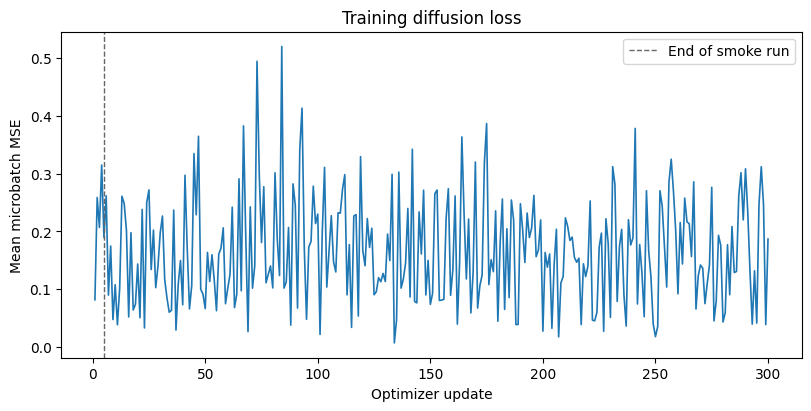

Final adapter: /content/drive/MyDrive/IE7615/milestone2/lora_finetuning/20261120T181318.093061Z/checkpoints/step-000300/pytorch_lora_weights.safetensors


In [14]:
import matplotlib.pyplot as plt
from IPython.display import display

if progress["step"] < SMOKE_STEPS:
    raise RuntimeError("Complete the smoke checks before full training.")
try:
    fit(MAX_STEPS)
except torch.cuda.OutOfMemoryError as error:
    raise RuntimeError(OOM_HELP) from error

final_checkpoint = save_checkpoint()
assert progress["step"] == len(history) == MAX_STEPS
assert (final_checkpoint / WEIGHT_NAME).is_file() and (final_checkpoint / "training_state.pt").is_file()
fig, axis = plt.subplots(figsize=(8, 4), layout="constrained")
axis.plot([row["optimizer_step"] for row in history], [row["loss"] for row in history], linewidth=1.2)
axis.axvline(SMOKE_STEPS, color="0.4", linestyle="--", linewidth=1, label="End of smoke run")
axis.set(title="Training diffusion loss", xlabel="Optimizer update", ylabel="Mean microbatch MSE")
axis.legend()
fig.savefig(run_dir / "training_loss.png", dpi=150)
display(fig)
plt.close(fig)
print(f"Final adapter: {final_checkpoint / WEIGHT_NAME}")

## 09 · Compare the pretrained model with the adapter

Release the training models and optimizer, then load a fresh copy of the same SD 1.5 checkpoint. Verify the saved weights loaded into the UNet and use the adapter at scale 1.0. For each held-out caption, use a fresh PNDM scheduler and identical seeds, raw latents, resolution, CFG, and negative prompt. Verify PEFT reports the adapter disabled for the baseline and enabled for the fine-tuned path. The standard prompt interface uses the same CLIP encoder, whose equivalence to explicit conditioning was checked in Notebook 05.

The paired images support qualitative review of prompt adherence and changes in composition, appearance, and artifacts. This small fixed set provides examples to inspect and cannot establish overall quality or generalization. FID and Inception Score are left to Milestone 3.

In [15]:
def prepare_comparison_pipeline():
    evaluation_pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, **model_kwargs).to(device)
    evaluation_pipe.set_progress_bar_config(leave=False)
    if not isinstance(evaluation_pipe.scheduler, PNDMScheduler):
        raise RuntimeError("The checkpoint does not have the expected PNDM scheduler.")
    evaluation_pipe.load_lora_weights(
        str(final_checkpoint), weight_name=WEIGHT_NAME, adapter_name="food", local_files_only=True,
    )
    evaluation_pipe.set_adapters(["food"], adapter_weights=[1.0])
    expected = convert_unet_state_dict_to_peft({
        key.removeprefix("unet."): tensor for key, tensor in load_file(final_checkpoint / WEIGHT_NAME).items()
    })
    loaded = get_peft_model_state_dict(evaluation_pipe.unet, adapter_name="food")
    if set(expected) != set(loaded) or not all(
        torch.equal(loaded[key].detach().cpu(), expected[key].to(loaded[key].dtype)) for key in expected
    ):
        raise RuntimeError("Loaded evaluation LoRA weights differ from the saved checkpoint.")
    status = get_model_status(evaluation_pipe.unet)
    assert status.enabled is True and status.active_adapters == ["food"] and status.merged_adapters == []
    print(f"Verified {len(expected)} saved tensors in {status.num_adapter_layers} active LoRA layers.")
    return evaluation_pipe


if "unet" in globals():
    del modules, unet, vae, text_encoder, optimizer, trainable, scaler
if "pipe" in globals():
    del pipe
gc.collect()
torch.cuda.empty_cache()
pipe = prepare_comparison_pipeline()
inference_scheduler_config = dict(pipe.scheduler.config)
if pipe.vae_scale_factor != 8 or pipe.unet.config.in_channels != 4:
    raise RuntimeError("Unexpected SD 1.5 latent shape for comparison.")

images_dir = run_dir / "comparison_images"
for variant in ("baseline", "lora"):
    (images_dir / variant).mkdir(parents=True, exist_ok=True)
comparison_metadata = {
    "checkpoint": str(final_checkpoint.relative_to(run_dir) / WEIGHT_NAME),
    "model_id": MODEL_ID, "revision": MODEL_REVISION, "runtime_session": session_number,
    "scheduler": "PNDMScheduler", "scheduler_config": inference_scheduler_config,
    "inference_settings": training_config["inference"],
    "prompt_selection": {"split": "val2017", "seed": SEED, "food_regex": FOOD_PATTERN,
                         "general_control_image_ids": list(general_controls)},
    "pairs": [],
}


@torch.inference_mode()
def compare_path(sample, noise_cpu, enabled):
    pipe.scheduler = PNDMScheduler.from_config(inference_scheduler_config)
    if enabled:
        pipe.enable_lora()
    else:
        pipe.disable_lora()
    state = get_model_status(pipe.unet)
    assert state.enabled is enabled and state.merged_adapters == []
    if enabled:
        assert state.active_adapters == ["food"]
    generator = torch.Generator(device="cpu").manual_seed(sample["seed"])
    initial_noise = noise_cpu.to(device, copy=True)
    torch.cuda.synchronize(device)
    started = perf_counter()
    output = pipe(
        prompt=sample["prompt"], negative_prompt=NEGATIVE_PROMPT,
        generator=generator, latents=initial_noise, **BASELINE,
    )
    torch.cuda.synchronize(device)
    seconds = perf_counter() - started
    variant = "lora" if enabled else "baseline"
    path = images_dir / variant / f"coco_{sample['image_id']:012d}_seed_{sample['seed']}.png"
    image = output.images[0]
    assert image.mode == "RGB" and image.size == (BASELINE["width"], BASELINE["height"])
    image.save(path)
    flags = output.nsfw_content_detected
    return {
        "image": path.relative_to(run_dir).as_posix(), "adapter_enabled": state.enabled,
        "actual_timesteps": pipe.scheduler.timesteps.detach().cpu().tolist(),
        "pipeline_seconds": seconds,
        "safety_checker_flag": bool(flags[0]) if flags is not None else None,
    }


for sample in evaluation:
    generator = torch.Generator(device="cpu").manual_seed(sample["seed"])
    noise_cpu = torch.randn((1, 4, 64, 64), generator=generator, device="cpu", dtype=torch.float32).to(dtype)
    base = compare_path(sample, noise_cpu, enabled=False)
    tuned = compare_path(sample, noise_cpu, enabled=True)
    assert base["actual_timesteps"] == tuned["actual_timesteps"] and base["actual_timesteps"]
    comparison_metadata["pairs"].append({
        **sample, "unscaled_fp16_noise_sha256": hashlib.sha256(noise_cpu.numpy().tobytes()).hexdigest(),
        "baseline": base, "lora": tuned,
    })
    write_json(run_dir / "comparison_runs.json", comparison_metadata)
    print(f"Saved pair · {sample['domain']} · COCO {sample['image_id']:012d} · seed {sample['seed']}")

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

... (17 outputs left out)

Saved pair · general · COCO 000000000139 · seed 7619


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Saved pair · general · COCO 000000000632 · seed 7620


### 09b · Save the comparison grids and training summary

Each grid row pairs the same caption and seed. The summary reports the actual data size, optimizer updates, loss, elapsed training time, measured CUDA allocation, and adapter checkpoint. Use the saved images to write any qualitative observations after the run.

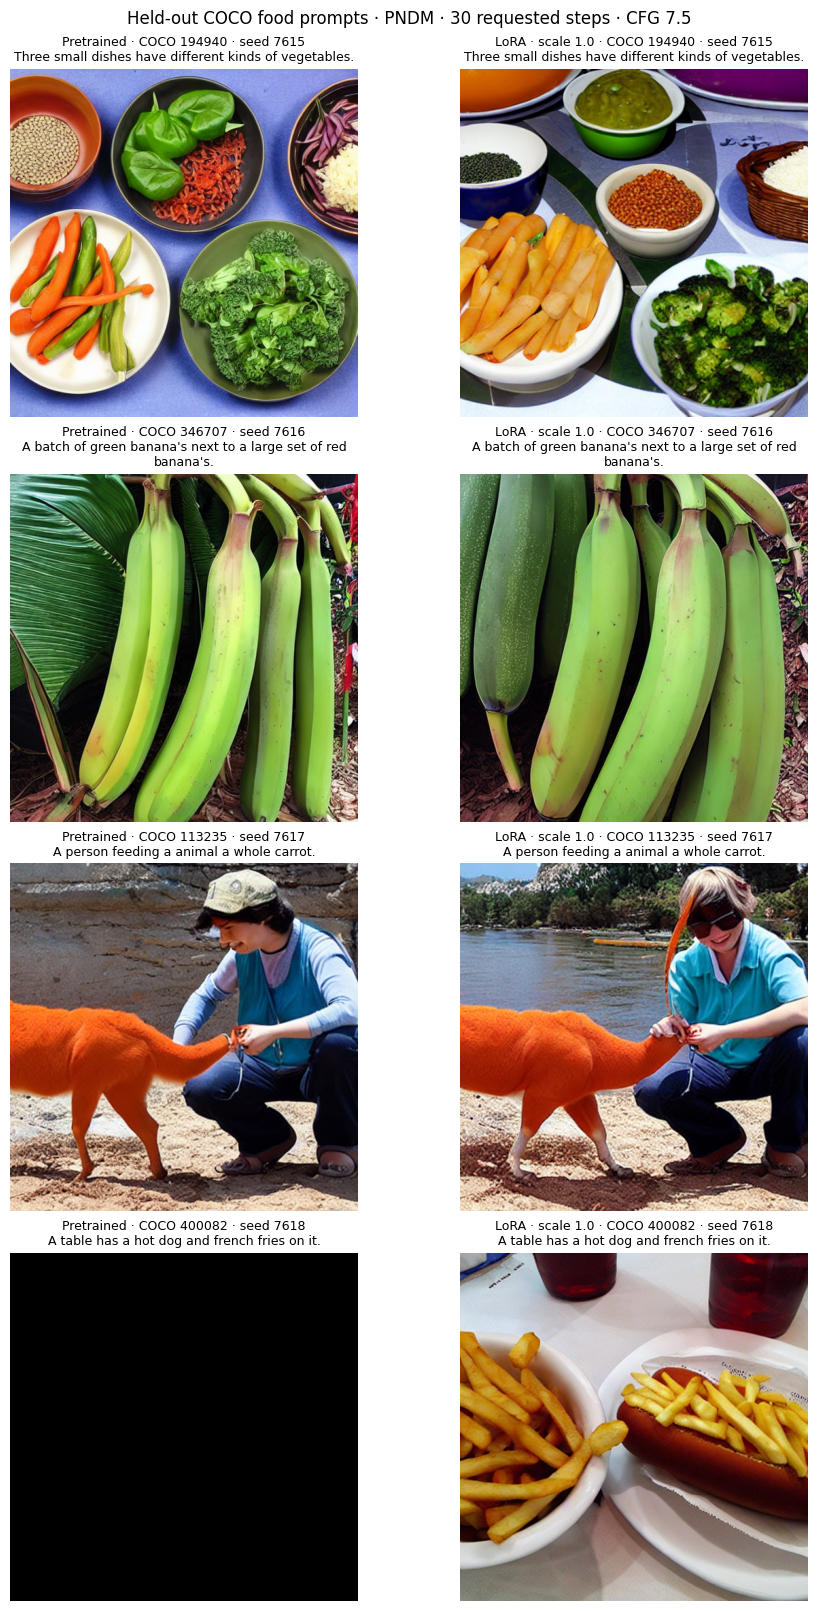

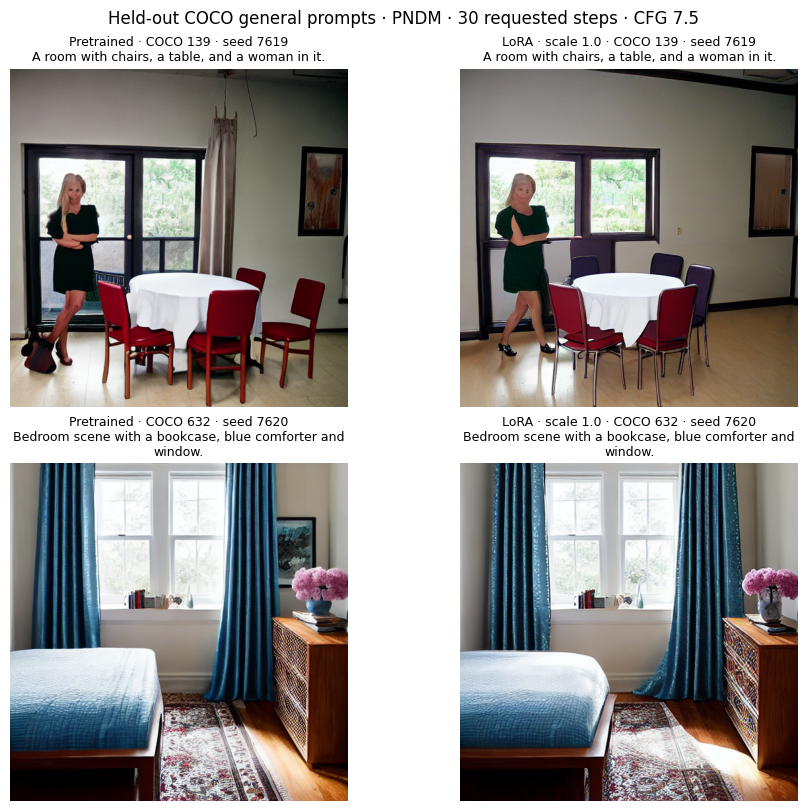

# IE 7615 · SD 1.5 LoRA training summary

Run: `20261120T181318.093061Z` · pinned checkpoint revision `451f4fe16113bff5a5d2269ed5ad43b0592e9a14`

| Measurement | Recorded value |
|---|---|
| Training split and images | COCO train2017 · 500 |
| Training image IDs also present in val2017 | 0 |
| Training resolution / LoRA rank | 512 × 512 / 8 |
| Trainable parameters | 1,594,368 (0.149% across CLIP, VAE, and UNet) |
| Optimizer updates / FP16 overflow skips | 300 / 0 |
| First / final logged training loss | 0.08165 / 0.18673 |
| Timed training updates | 10.43 min |
| Peak allocated CUDA memory* | 4.06 GiB |
| Held-out prompt pairs | 6 (four food, two general) |

*Maximum PyTorch allocation across logged updates. Load time and unlogged work are outside these measurements.

[Final adapter](checkpoints/step-000300/pytorch_lora_weights.safetensors) · [Training plot](training_loss.png) · [Food grid](food_comparison_grid.png) · [General grid](general_comparison_grid.png)

The loss describes the training denoising objective. Compare the paired held-out images to assess what changed.


Verified the logs, final checkpoint, and twelve held-out comparison images in /content/drive/MyDrive/IE7615/milestone2/lora_finetuning/20261120T181318.093061Z


In [17]:
import textwrap
from IPython.display import Markdown, display

pairs = comparison_metadata["pairs"]
assert len(pairs) == 6
grid_names = {}
for domain in ("food", "general"):
    subset = [sample for sample in pairs if sample["domain"] == domain]
    figure, axes = plt.subplots(len(subset), 2, figsize=(9, 4.0 * len(subset)),
                                squeeze=False, layout="constrained")
    figure.suptitle(f"Held-out COCO {domain} prompts · PNDM · 30 requested steps · CFG 7.5")
    for row_index, sample in enumerate(subset):
        for column, (variant, title) in enumerate((("baseline", "Pretrained"), ("lora", "LoRA · scale 1.0"))):
            axis = axes[row_index, column]
            with Image.open(run_dir / sample[variant]["image"]) as image:
                axis.imshow(np.asarray(image))
            axis.set_axis_off()
            caption = textwrap.fill(sample["prompt"], width=55)
            axis.set_title(f"{title} · COCO {sample['image_id']} · seed {sample['seed']}\n{caption}", fontsize=9)
    grid = run_dir / f"{domain}_comparison_grid.png"
    figure.savefig(grid, dpi=150, facecolor="white")
    display(figure)
    plt.close(figure)
    grid_names[domain] = grid.name

comparison_metadata["grids"] = grid_names
write_json(run_dir / "comparison_runs.json", comparison_metadata)
for sample in pairs:
    for variant in ("baseline", "lora"):
        with Image.open(run_dir / sample[variant]["image"]) as image:
            assert image.size == (512, 512)
            image.verify()

summary = "\n".join([
    "# IE 7615 · SD 1.5 LoRA training summary",
    "",
    f"Run: `{run_id}` · pinned checkpoint revision `{MODEL_REVISION}`",
    "",
    "| Measurement | Recorded value |",
    "|---|---|",
    f"| Training split and images | COCO train2017 · {len(training_rows):,} |",
    "| Training image IDs also present in val2017 | 0 |",
    f"| Training resolution / LoRA rank | {TRAIN_RESOLUTION} × {TRAIN_RESOLUTION} / {LORA_RANK} |",
    f"| Trainable parameters | {parameter_summary['trainable_parameters']:,} "
    f"({parameter_summary['trainable_percent_all_components']:.3f}% across CLIP, VAE, and UNet) |",
    f"| Optimizer updates / FP16 overflow skips | {progress['step']} / {progress['skipped_overflows']} |",
    f"| First / final logged training loss | {history[0]['loss']:.5f} / {history[-1]['loss']:.5f} |",
    f"| Timed training updates | {progress['elapsed_seconds'] / 60:.2f} min |",
    f"| Peak allocated CUDA memory* | {max(row['peak_allocated_gib'] for row in history):.2f} GiB |",
    f"| Held-out prompt pairs | {len(pairs)} (four food, two general) |",
    "",
    "*Maximum PyTorch allocation across logged updates. Load time and unlogged work are outside these measurements.",
    "",
    f"[Final adapter]({comparison_metadata['checkpoint']}) · [Training plot](training_loss.png) · "
    f"[Food grid]({grid_names['food']}) · [General grid]({grid_names['general']})",
    "",
    "The loss describes the training denoising objective. Compare the paired held-out images to assess what changed.",
    "",
])
(run_dir / "summary.md").write_text(summary, encoding="utf-8")
with (run_dir / "training_log.csv").open(encoding="utf-8", newline="") as handle:
    assert len(list(csv.DictReader(handle))) == len(history)
assert all((run_dir / name).is_file() for name in (
    "training_dataset.json", "parameter_summary.json", "training_config.json",
    "runtime_sessions.json", "smoke_checks.json", "training_log.json", "training_loss.png",
    "comparison_runs.json", *grid_names.values(), "summary.md",
))
display(Markdown(summary))
print(f"Verified the logs, final checkpoint, and twelve held-out comparison images in {run_dir}")

  0%|          | 0/30 [00:00<?, ?it/s]

Pretrained Safety flagged: [False]


  0%|          | 0/30 [00:00<?, ?it/s]

Fine-tuned LoRA Safety flagged: [False]


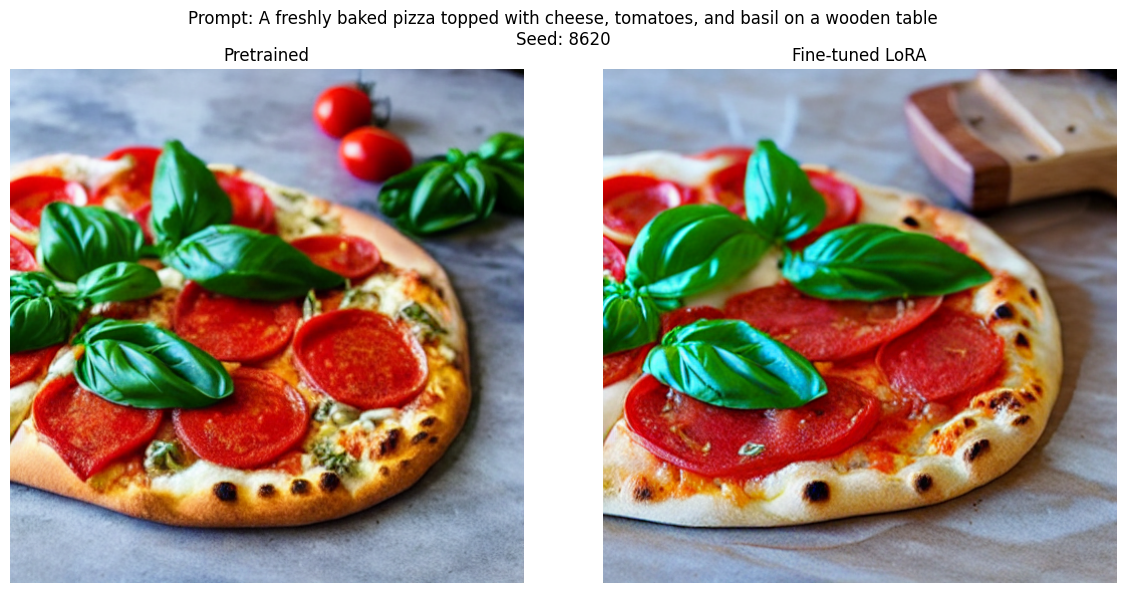

Saved: /content/drive/MyDrive/IE7615/milestone2/lora_finetuning/20261120T181318.093061Z/additional_pizza_comparison.png


In [18]:

# Generate a NEW food comparison without retraining

from IPython.display import display
import matplotlib.pyplot as plt
import torch

prompt = "A freshly baked pizza topped with cheese, tomatoes, and basil on a wooden table"
seed = 8620

generator = torch.Generator(device="cpu").manual_seed(seed)
noise = torch.randn(
    (1, 4, 64, 64),
    generator=generator,
    dtype=torch.float32
).to(device=device, dtype=dtype)

results = {}

for name, use_lora in [("Pretrained", False), ("Fine-tuned LoRA", True)]:
    pipe.scheduler = PNDMScheduler.from_config(inference_scheduler_config)

    if use_lora:
        pipe.enable_lora()
    else:
        pipe.disable_lora()

    with torch.inference_mode():
        output = pipe(
            prompt=prompt,
            negative_prompt=NEGATIVE_PROMPT,
            latents=noise.clone(),
            **BASELINE
        )

    results[name] = output.images[0]

    print(
        name,
        "Safety flagged:",
        output.nsfw_content_detected
    )

# Display comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, (name, image) in zip(axes, results.items()):
    ax.imshow(image)
    ax.set_title(name)
    ax.axis("off")

plt.suptitle(f"Prompt: {prompt}\nSeed: {seed}")
plt.tight_layout()
display(fig)

# Save new comparison separately
output_path = run_dir / "additional_pizza_comparison.png"
fig.savefig(output_path, dpi=150)
plt.close(fig)

pipe.enable_lora()
print("Saved:", output_path)
